# SpaceSleepTwin — HERA quantitative benchmark (exploratory)
Notebook autossuficiente para Kaggle: numpy, pandas, scipy, matplotlib. Não requer dados pessoais nem Internet. Usa o motor do notebook simulacao_spacesleeptwin.ipynb, sem reajustar seus parâmetros.

**Objetivo:** comparar o contraste de fase DLS−SLS do oscilador com o contraste agregado publicado. Isto é um benchmark exploratório; não valida previsões individuais, latência, intervenções em voo ou um gêmeo digital completo.

## Dados publicados e hipóteses
Fonte: Rahman et al., J Pineal Res. 2022, DOI [10.1111/jpi.12826](https://doi.org/10.1111/jpi.12826), [texto e Tabela 1](https://pmc.ncbi.nlm.nih.gov/articles/PMC11316501/).
Sono: 23–07 h (duas noites), 02–07 h (cinco noites), repetidos. DLS reduz luz três horas antes de deitar. Janela de coleta: 48 h iniciadas nos dias 5,12,19,26,33,43.
Alvo agregado: acrofase urinária aMT6s SLS 6,22 h; DLS 4,76 h; contraste −1,46 h. Pré-missão: SLS 4,24 h; DLS 3,69 h: diferença entre mudanças −0,91 h, apenas descritiva.

Entradas verticais da Tabela 1:
| Cenário | SLS dia/tarde | DLS dia | DLS tarde |
|---|---:|---:|---:|
| L1 fotópico | 122 | 264 | 13 |
| L2 fotópico | 143 | 80 | 4 |
| L1 melEDI (proxy experimental) | 89 | 233 | 8 |

Lux fotópico é a entrada original. **melEDI não é intercambiável com lux fotópico**: a terceira linha testa apenas a sensibilidade de uma substituição ingênua; não representa um modelo espectral validado.

Hipóteses não observadas: permanência no mesmo nível durante vigília; ausência de luz nos olhos durante sono; 21 dias prévios em 150 lux e sono 23–07 h; mesma fase inicial entre grupos; primeiro ciclo começa com duas noites longas. Exploram-se todas as sete posições do ciclo e τ=23,8/24,2/24,6 h, sem selecionar a que mais se aproxima do alvo.

## Medida do modelo
Extrai mínimos de x e compara horários por diferenças circulares. Não usa atan2 diário como horário de pico de melatonina. x-min é um proxy circadiano; para vinculá-lo a aMT6s seria necessária uma relação entre marcadores validada. Um deslocamento fixo comum cancelaria no contraste, mas não podemos presumir que seja constante entre condições.

Referência do modelo: [Forger, Jewett & Kronauer (1999), A Simpler Model of the Human Circadian Pacemaker](https://doi.org/10.1177/074873099129000867).
Não é um modelo de secreção ou excreção de melatonina. Coletas urinárias reais foram ajustadas por cosinor; aqui se usa média circular dos mínimos nas janelas, não reanálise da urina.

## Interpretação
Resultado na direção esperada é consistência qualitativa. Proximidade numérica é concordância descritiva, não confirmação independente: alvo já conhecido, exposição individual desconhecida e marcadores diferentes. Não há critério de aprovação pós-hoc nem intervalos de confiança inventados. As médias publicadas vêm de modelo misto; nossa média das seis janelas não reproduz esse estimador.

A exposição noturna reduzida em dois estágios e a movimentação entre ambientes requerem o suplemento e registros individuais para uma reprodução mais fiel. O cenário L1 resume as três horas finais em 13 lux.

Separar prever de reduzir: previsão demanda avaliação em pessoas/noites futuras; redução exige comparação de intervenção. HERA é análogo terrestre. Dados individuais são disponibilizados mediante pedido ao LSDA segundo o artigo. Isso não prova ausência de qualquer outro conjunto público de astronautas.



In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from IPython.display import display
import sys, scipy
print("Python", sys.version.split()[0], "SciPy", scipy.__version__)
OBSERVED_DELTA = 4.76 - 6.22
SAMPLE_DAYS = [5,12,19,26,33,43]
# Table 1: eye-level vertical measurements. Photopic is native Forger99 input.
LIGHTS = {
 "L1_photopic": {"SLS": (122.,122.), "DLS": (264.,13.)},
 "L2_photopic": {"SLS": (143.,143.), "DLS": (80.,4.)},
 "L1_melEDI_proxy": {"SLS": (89.,89.), "DLS": (233.,8.)},
}
def derivative(t, y, tau, intensity):
    x, xc, n = y
    alpha = .05 * (intensity/9500.)**.5 if intensity > 0 else 0.
    B = 33.75*(1-n)*alpha*(1-.4*x)*(1-.4*xc)
    return [np.pi/12*(xc+B),
            np.pi/12*(.23*(xc-4*xc**3/3)-x*((24/(.99669*tau))**2+.55*B)),
            60*(alpha*(1-n)-.0075*n)]
def integrate_segment(start, end, state, tau, intensity, step):
    grid = np.linspace(start,end,int(np.ceil((end-start)/step))+1)
    sol = solve_ivp(lambda t,y: derivative(t,y,tau,intensity),(start,end),state,
                    t_eval=grid,rtol=1e-8,atol=1e-10,max_step=.25)
    assert sol.success, sol.message
    return sol.t, sol.y
def run(condition, tau=24.2, location="L1_photopic", cycle_offset=0, step=1/12):
    # Common premission equilibration is an assumption, not measured HERA exposure.
    state = np.array([1.,0.,.5])
    for day in range(-21,0):
        _, v = integrate_segment(day*24,day*24+16,state,tau,150.,step)
        _, w = integrate_segment(day*24+16,(day+1)*24,v[:,-1],tau,0.,step)
        state = w[:,-1]
    ts, xs = [], []
    for day in range(45):
        # t=0 is 07:00; two 8h nights followed by five 5h nights.
        awake = 16. if (day+cycle_offset)%7 < 2 else 19.
        daytime, evening = LIGHTS[location][condition]
        segments = [(0,awake-3,daytime),(awake-3,awake,evening),(awake,24,0.)]
        for start,end,I in segments:
            t,v=integrate_segment(day*24+start,day*24+end,state,tau,I,step)
            state=v[:,-1]; ts.extend(t[:-1]); xs.extend(v[0,:-1])
    ts=np.array(ts); xs=np.array(xs)
    # x minima: phase proxy, not predicted urinary melatonin concentrations.
    peaks,_=find_peaks(-xs,distance=int(18/step))
    times=[]
    for i in peaks:
        if i<1 or i>=len(xs)-1: continue
        a,b,c=xs[i-1:i+2]
        shift=.5*(a-c)/(a-2*b+c)
        times.append(ts[i]+np.clip(shift,-1,1)*(ts[i+1]-ts[i]))
    times=np.array(times)
    rows=[]
    for md in SAMPLE_DAYS:
        selected=times[(times >= (md-1)*24)&(times < (md+1)*24)]
        clock=(selected+7)%24
        # Circular mean avoids a midnight wrap.
        angle=np.mean(np.exp(2j*np.pi*clock/24))
        h=np.angle(angle)*24/(2*np.pi)%24
        rows.append({"mission_day":md,"phase_proxy_h":h,"minima_count":len(selected)})
    return pd.DataFrame(rows)
def circ_diff(a,b):
    return (a-b+12)%24-12
def compare(**kwargs):
    s=run("SLS",**kwargs); d=run("DLS",**kwargs)
    assert (s.minima_count > 0).all() and (d.minima_count > 0).all()
    out=s[["mission_day"]].copy()
    out["SLS_proxy_h"]=s.phase_proxy_h
    out["DLS_proxy_h"]=d.phase_proxy_h
    out["DLS_minus_SLS_h"]=circ_diff(d.phase_proxy_h,s.phase_proxy_h)
    return out
primary=compare()
display(primary.round(3))
delta=float(primary.DLS_minus_SLS_h.mean())
print(f"Primary proxy contrast: {delta:.3f} h; observed urinary contrast: {OBSERVED_DELTA:.3f} h")
print(f"Descriptive discrepancy: {abs(delta-OBSERVED_DELTA)*60:.1f} min (different markers)")



Python 3.12.14 SciPy 1.17.0
   mission_day  SLS_proxy_h  DLS_proxy_h  DLS_minus_SLS_h
0            5        5.577        4.557           -1.019
1           12        5.925        4.591           -1.334
2           19        5.991        4.596           -1.395
3           26        6.003        4.596           -1.407
4           33        6.005        4.596           -1.409
5           43        5.591        4.180           -1.410
Primary proxy contrast: -1.329 h; observed urinary contrast: -1.460 h
Descriptive discrepancy: 7.9 min (different markers)


            scenario  value  contrast_h
0       cycle_offset      0      -1.329
1       cycle_offset      1      -1.334
2       cycle_offset      2      -1.335
3       cycle_offset      3      -1.330
4       cycle_offset      4      -1.329
5       cycle_offset      5      -1.328
6       cycle_offset      6      -1.327
7   intrinsic_period   23.8      -0.690
8   intrinsic_period   24.6      -1.133
9        L2_photopic  input      -1.113
10   L1_melEDI_proxy  input      -1.433
5 versus 2.5 min output grid: maximum contrast difference = 0.0014 min
Identical-light control: zero contrast confirmed
Sensitivity ranges are scenarios, not confidence intervals.


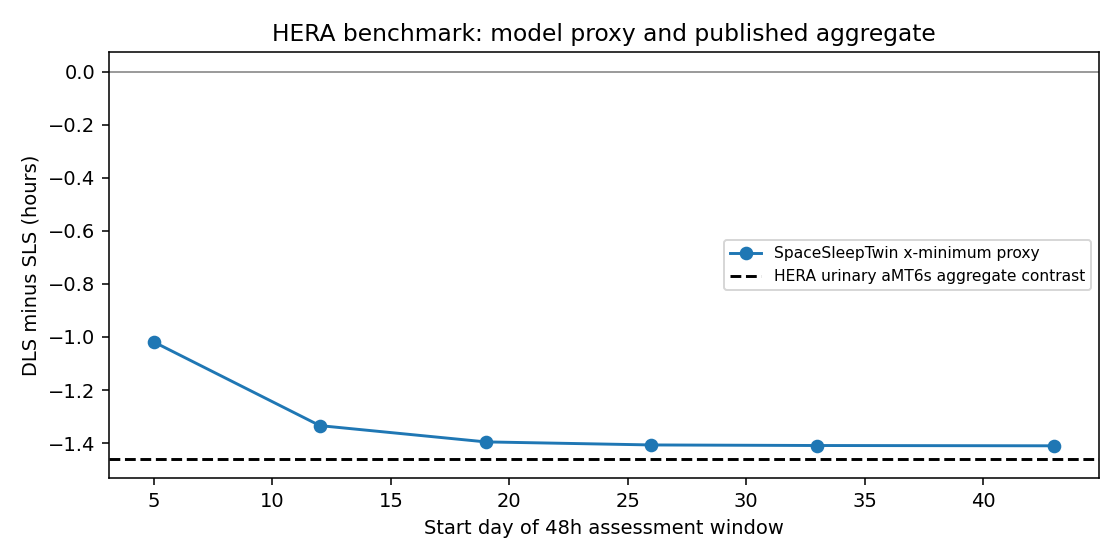

In [2]:
rows=[]
for offset in range(7):
    c=compare(cycle_offset=offset)
    rows.append(dict(scenario="cycle_offset",value=offset,contrast_h=c.DLS_minus_SLS_h.mean()))
for tau in [23.8,24.6]:
    c=compare(tau=tau)
    rows.append(dict(scenario="intrinsic_period",value=tau,contrast_h=c.DLS_minus_SLS_h.mean()))
for loc in ["L2_photopic","L1_melEDI_proxy"]:
    c=compare(location=loc)
    rows.append(dict(scenario=loc,value="input",contrast_h=c.DLS_minus_SLS_h.mean()))
sensitivity=pd.DataFrame(rows)
display(sensitivity.round(3))
fine=compare(step=1/24)
diff=np.max(np.abs(fine.DLS_minus_SLS_h-primary.DLS_minus_SLS_h))*60
print(f"5 versus 2.5 min output grid: maximum contrast difference = {diff:.4f} min")
assert diff < .5, "Inspect numerical convergence"
identical=LIGHTS["L1_photopic"]["DLS"]
try:
    LIGHTS["L1_photopic"]["DLS"]=LIGHTS["L1_photopic"]["SLS"]
    null=compare()
    assert np.max(np.abs(null.DLS_minus_SLS_h))<1e-8
finally:
    LIGHTS["L1_photopic"]["DLS"]=identical
print("Identical-light control: zero contrast confirmed")
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(primary.mission_day,primary.DLS_minus_SLS_h,"o-",label="SpaceSleepTwin x-minimum proxy")
ax.axhline(OBSERVED_DELTA,color="black",ls="--",label="HERA urinary aMT6s aggregate contrast")
ax.axhline(0,color="gray",lw=.8)
ax.set(xlabel="Start day of 48h assessment window",ylabel="DLS minus SLS (hours)",
       title="HERA benchmark: model proxy and published aggregate")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()
print("Sensitivity ranges are scenarios, not confidence intervals.")



## Resultado executado e conclusão
Contraste principal DLS−SLS: **−1,329 h**. Alvo agregado publicado: **−1,460 h**. Discrepância descritiva: **7,9 min**. Não ajustamos parâmetros para minimizar essa discrepância.

A posição do ciclo semanal produziu −1,335 a −1,327 h. Com τ=23,8 h, o contraste foi −0,690 h; com τ=24,6 h, −1,133 h. O cenário fotópico L2 produziu −1,113 h. O proxy melEDI produziu −1,433 h, mas não pode ser usado para escolher ou validar a entrada espectral. O resultado depende de hipóteses fisiológicas e de exposição; não inferimos acurácia individual a partir da proximidade entre médias.

Controle com luz idêntica: contraste zero. Refinamento da grade de saída de 5 para 2,5 minutos: diferença máxima de contraste 0,0014 min. Isto verifica implementação numérica, não validade biológica.

**Formulação defensável:** sob uma reconstrução simplificada da iluminação e do sono do HERA, o componente circadiano do SpaceSleepTwin reproduziu a direção e aproximou a magnitude do contraste agregado publicado. A comparação entre marcadores distintos permanece exploratória. Não demonstra benefício em astronautas nem valida previsão individual.

Próximos passos: auditar suplemento e exposição pessoal; estabelecer a relação entre x-min e acrofase aMT6s; obter dados individuais LSDA; fixar parâmetros e protocolo antes de testar outra missão/coorte. Os valores agregados já conhecidos não constituem conjunto reservado.

Execução: células rodadas sequencialmente em Python 3.12.14/SciPy 1.17.0; dependências científicas disponíveis no Kaggle. A publicação e execução dentro da conta Kaggle não foram feitas.


## Factorial decomposition of light inputs (exploratory)
Four counterfactual schedules hold sleep timing, initial phase and all model parameters constant. The partial schedules are not HERA treatment arms: they isolate changes in this model, not causal effects in the observed participants. Day-only changes the early waking input; evening-only changes the last three waking hours. Sleep remains dark in every arm.

Primary contrasts use 48h windows and a refined 30-second output grid. The interaction is Δ(full)−Δ(day-only)−Δ(evening-only); it describes nonadditivity in the oscillator. Do not treat partial effects as additive percentages. Sensitivity spans the predefined two habitat levels and three intrinsic periods.

The model receives photopic lux and cannot represent the published spectral change. Photopic eye-level and melanopic horizontal measurements cannot be directly compared as a matched spectral ratio. Whether omission underestimates the physiological contrast has not been demonstrated here.


   mission_day  SLS  DAY_ONLY  EVENING_ONLY     DLS  interaction_h
0            5  0.0   -0.3628       -0.8254 -1.0193         0.1689
1           12  0.0   -0.5263       -1.0681 -1.3340         0.2603
2           19  0.0   -0.5645       -1.1119 -1.3954         0.2811
3           26  0.0   -0.5726       -1.1194 -1.4069         0.2851
4           33  0.0   -0.5742       -1.1206 -1.4090         0.2858
5           43  0.0   -0.6211       -1.0277 -1.4101         0.2388
SLS              0.0000
DAY_ONLY        -0.5369
EVENING_ONLY    -1.0455
DLS             -1.3291
interaction_h    0.2533
      location   tau  SLS  DAY_ONLY  EVENING_ONLY     DLS  interaction_h
0  L1_photopic  23.8  0.0   -0.1042       -0.8958 -0.6902         0.3098
1  L1_photopic  24.2  0.0   -0.5369       -1.0455 -1.3291         0.2533
2  L1_photopic  24.6  0.0   -0.3765       -0.5592 -1.1425        -0.2068
3  L2_photopic  23.8  0.0    0.1847       -1.0438 -1.2642        -0.4051
4  L2_photopic  24.2  0.0    0.4842       -1.3

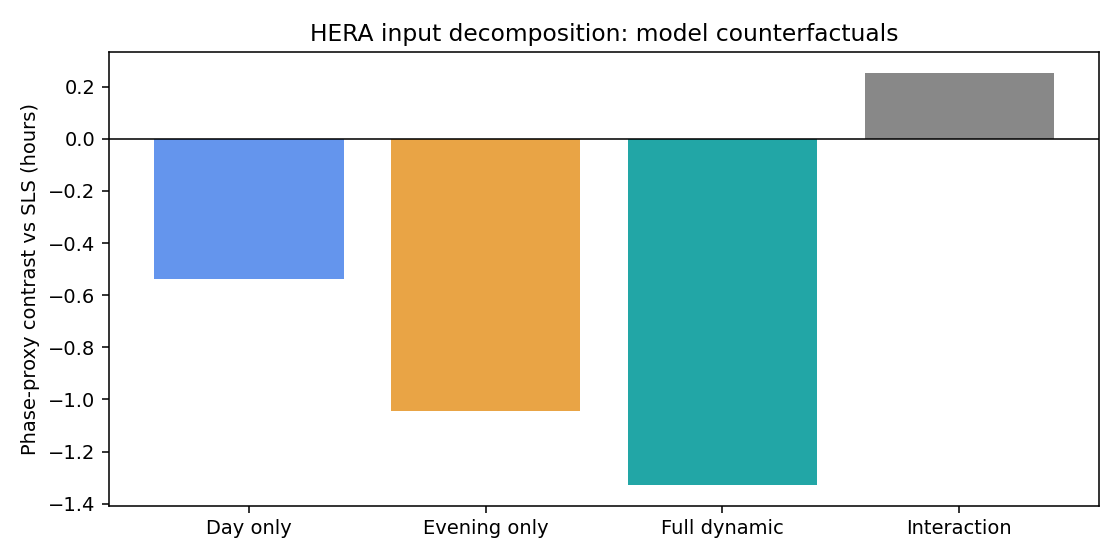

In [3]:
# Four schedules with identical initial state and sleep timing.
# Sleep exposure remains zero; "evening" means the last 3h awake.
for levels in LIGHTS.values():
    standard_day, standard_evening = levels["SLS"]
    dynamic_day, dynamic_evening = levels["DLS"]
    levels["DAY_ONLY"] = (dynamic_day, standard_evening)
    levels["EVENING_ONLY"] = (standard_day, dynamic_evening)

def decompose(tau=24.2, location="L1_photopic", step=1/120):
    phases={c:run(c,tau=tau,location=location,step=step) for c in ["SLS","DAY_ONLY","EVENING_ONLY","DLS"]}
    result=phases["SLS"][["mission_day"]].copy()
    for c in phases:
        result[c]=circ_diff(phases[c].phase_proxy_h,phases["SLS"].phase_proxy_h)
    result["interaction_h"]=result.DLS-result.DAY_ONLY-result.EVENING_ONLY
    return result

factorial=decompose()
display(factorial.round(4))
means=factorial.drop(columns="mission_day").mean()
display(means.round(4))
checks=[]
for location in ["L1_photopic","L2_photopic"]:
    for tau in [23.8,24.2,24.6]:
        values=decompose(tau=tau,location=location).drop(columns="mission_day").mean()
        checks.append(dict(location=location,tau=tau,**values.to_dict()))
factorial_sensitivity=pd.DataFrame(checks)
display(factorial_sensitivity.round(4))
assert np.max(np.abs(factorial.SLS))<1e-9
assert np.allclose(factorial.DLS,factorial.DAY_ONLY+factorial.EVENING_ONLY+factorial.interaction_h)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(["Day only","Evening only","Full dynamic","Interaction"],
       means[["DAY_ONLY","EVENING_ONLY","DLS","interaction_h"]],color=["#6495ed","#e9a445","#22a6a6","#888888"])
ax.axhline(0,color="black",lw=.8)
ax.set(ylabel="Phase-proxy contrast vs SLS (hours)",title="HERA input decomposition: model counterfactuals")
fig.tight_layout();plt.show()
print("Negative = earlier phase. The interaction is full minus the two partial contrasts.")
print("No percent attribution: the oscillator is nonlinear, and these scenarios were not observed HERA arms.")


## Sleep-schedule and metric sensitivity (fixed before evaluation)
These tests use τ=24.2 h, 45 days and the six fixed assessment windows. Conventional sleep is 23:00–07:00 every night, with dimming at 20:00. HERA alternates two 8h and five 5h nights. Both use the same assumed premission state. The change therefore combines sleep timing and opportunity duration; it does not isolate bedtime independently of sleep duration.

The spectral sensitivity test substitutes the matched eye-level L1 melanopic EDI inputs already present in the notebook (SLS 89; DLS day 233, evening 8). Forger99 remains a photopic-input model: this substitution is an unvalidated proxy, not proof of spectral robustness in people. Record all four combinations without choosing a favorable one.


In [4]:
# Fixed before evaluating: 45 days, τ=24.2 h, common premission state,
# same six windows; HERA schedule vs seven 23:00–07:00 nights per week.
# Eye-level L1 photopic vs naive eye-level L1 melEDI substitution.
import inspect
# Notebook standalone definition of modified run: needed for reproducibility.
def run(condition, tau=24.2, location="L1_photopic", cycle_offset=0, step=1/12, conventional=False):
    # Common premission equilibration is an assumption, not measured HERA exposure.
    state = np.array([1.,0.,.5])
    for day in range(-21,0):
        _, v = integrate_segment(day*24,day*24+16,state,tau,150.,step)
        _, w = integrate_segment(day*24+16,(day+1)*24,v[:,-1],tau,0.,step)
        state = w[:,-1]
    ts, xs = [], []
    for day in range(45):
        # t=0 is 07:00; two 8h nights followed by five 5h nights.
        awake = 16. if conventional or (day+cycle_offset)%7 < 2 else 19.
        daytime, evening = LIGHTS[location][condition]
        segments = [(0,awake-3,daytime),(awake-3,awake,evening),(awake,24,0.)]
        for start,end,I in segments:
            t,v=integrate_segment(day*24+start,day*24+end,state,tau,I,step)
            state=v[:,-1]; ts.extend(t[:-1]); xs.extend(v[0,:-1])
    ts=np.array(ts); xs=np.array(xs)
    # x minima: phase proxy, not predicted urinary melatonin concentrations.
    peaks,_=find_peaks(-xs,distance=int(18/step))
    times=[]
    for i in peaks:
        if i<1 or i>=len(xs)-1: continue
        a,b,c=xs[i-1:i+2]
        shift=.5*(a-c)/(a-2*b+c)
        times.append(ts[i]+np.clip(shift,-1,1)*(ts[i+1]-ts[i]))
    times=np.array(times)
    rows=[]
    for md in SAMPLE_DAYS:
        selected=times[(times >= (md-1)*24)&(times < (md+1)*24)]
        clock=(selected+7)%24
        # Circular mean avoids a midnight wrap.
        angle=np.mean(np.exp(2j*np.pi*clock/24))
        h=np.angle(angle)*24/(2*np.pi)%24
        rows.append({"mission_day":md,"phase_proxy_h":h,"minima_count":len(selected)})
    return pd.DataFrame(rows)

for levels in LIGHTS.values():
    sd,se=levels["SLS"];dd,de=levels["DLS"]
    levels["DAY_ONLY"]=(dd,se);levels["EVENING_ONLY"]=(sd,de)
records=[]
for conventional in [False,True]:
    for location in ["L1_photopic","L1_melEDI_proxy"]:
        phases={c:run(c,tau=24.2,location=location,step=1/120,conventional=conventional)
                for c in ["SLS","DAY_ONLY","EVENING_ONLY","DLS"]}
        contrasts={c:float(circ_diff(phases[c].phase_proxy_h,phases["SLS"].phase_proxy_h).mean()) for c in phases}
        records.append(dict(schedule="conventional_23_07" if conventional else "HERA_variable",
                            metric=location,**contrasts,
                            interaction_h=contrasts["DLS"]-contrasts["DAY_ONLY"]-contrasts["EVENING_ONLY"]))
robustness=pd.DataFrame(records)
display(robustness.round(4))
assert all(abs(r["SLS"])<1e-9 for r in records)
print("Comparison of relative effects is limited to these fixed model settings.")
print("melEDI substitution changes the numeric forcing, not the validated spectral sensitivity of Forger99.")


             schedule           metric  SLS  DAY_ONLY  EVENING_ONLY     DLS  interaction_h
0       HERA_variable      L1_photopic  0.0   -0.5369       -1.0455 -1.3291         0.2533
1       HERA_variable  L1_melEDI_proxy  0.0   -0.6777       -1.0832 -1.4326         0.3282
2  conventional_23_07      L1_photopic  0.0   -0.4947       -1.0151 -1.3929         0.1170
3  conventional_23_07  L1_melEDI_proxy  0.0   -0.6395       -1.0595 -1.5340         0.1650
Comparison of relative effects is limited to these fixed model settings.
melEDI substitution changes the numeric forcing, not the validated spectral sensitivity of Forger99.


## Absolute alignment: premission anchoring and assumed uncertainty
Target aMT6s window: 02:45–05:39; center 04:12. Mapping is fitted using only published premission means (SLS 4.24 h; DLS 3.69 h), then evaluated against known mission means. The assumed model premission routine is not observed exposure. Separate group offsets absorb group phase differences and do not establish a universal biological marker mapping. A shared-offset alternative is also reported.

Daily metrics are model fractions and distances, not measured daily biomarkers or a reproduction of the study's individual alignment percentages. Greater advance is not automatically better alignment. A constant-offset mapping between x-min and aMT6s is an unvalidated assumption.

Uncertainty uses 24 matched, synthetic Monte Carlo draws from explicitly assumed distributions of tau and initial phase error. The common 3.965 h starting anchor represents a hypothetical subject, not either HERA group or an individual astronaut. The probability is conditional on these assumptions, not a calibrated patient/astronaut posterior. Finite Monte Carlo sampling and uncertainty about model structure remain. Individual premission measures and exposure are needed to estimate actual calibration uncertainty.

Initial-phase error is implemented as a nominal-hour rotation of the oscillator state, not a validated mapping from angular phase to measured clock-time uncertainty. All 24 assumed-prior draws favored DLS by distance; this is a finite synthetic sample, not certainty for an individual.


{
  "primary": [
    {
      "condition": "SLS",
      "pre_anchor_h": 4.24,
      "prediction_h": 5.7952026295613654,
      "observed_h": 6.22,
      "absolute_circular_error_h": 0.4247973704386343,
      "predicted_mean_inside": false,
      "observed_mean_inside": false,
      "daily_fraction_inside": 0.4444444444444444,
      "daily_mean_distance_h": 1.4421436677683972
    },
    {
      "condition": "DLS",
      "pre_anchor_h": 3.69,
      "prediction_h": 3.9161162501058993,
      "observed_h": 4.76,
      "absolute_circular_error_h": 0.8438837498941005,
      "predicted_mean_inside": true,
      "observed_mean_inside": true,
      "daily_fraction_inside": 1.0,
      "daily_mean_distance_h": 0.40349050758098537
    }
  ],
  "shared_offset_predictions": {
    "SLS": 5.520202629561365,
    "DLS": 4.1911162501059
  },
  "uncertainty_assumptions": {
    "tau": "Normal(24.2,0.15), truncated to [23.8,24.6]",
    "initial_phase_error": "Normal(0,0.25 h), truncated to [-1,1] h",
    "shar

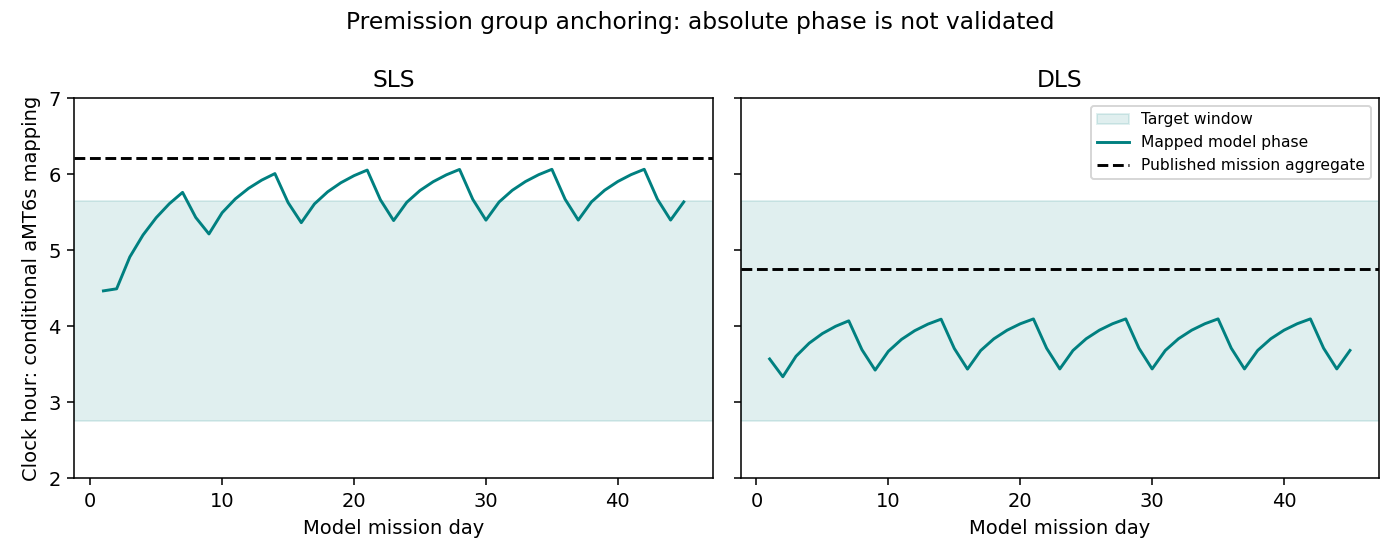

In [5]:
"""Premission anchoring and assumed-prior alignment sensitivity, not individual validation."""
import numpy as np, pandas as pd
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
import json, pathlib, io, contextlib

TARGET=(2.75,5.65)
PRE={'SLS':4.24,'DLS':3.69}
MISSION={'SLS':6.22,'DLS':4.76}
WINDOWS=[5,12,19,26,33,43]

def circular_difference(a,b): return (np.asarray(a)-b+12)%24-12
def circular_mean(a): return np.angle(np.mean(np.exp(np.asarray(a)*2j*np.pi/24)))*24/(2*np.pi)%24
def metrics(phases,target=TARGET):
    start,end=target; width=(end-start)%24
    if width<=0 or width>=12: raise ValueError('Target width must be in (0,12) hours')
    center=(start+width/2)%24
    return {'mean_distance_to_center_h':float(np.mean(np.abs(circular_difference(phases,center)))),
            'fraction_in_window':float(np.mean((np.asarray(phases)-start)%24<=width))}

def model_rhs(t,y,tau,I):
    x,xc,n=y;alpha=.05*np.sqrt(I/9500) if I>0 else 0.
    B=33.75*(1-n)*alpha*(1-.4*x)*(1-.4*xc)
    return [np.pi/12*(xc+B),np.pi/12*(.23*(xc-4*xc**3/3)-x*((24/(.99669*tau))**2+.55*B)),60*(alpha*(1-n)-.0075*n)]

def evolve(start,end,state,tau,I,step=1/120):
    grid=np.linspace(start,end,int(np.ceil((end-start)/step))+1)
    sol=solve_ivp(lambda t,y:model_rhs(t,y,tau,I),(start,end),state,t_eval=grid,
                  rtol=1e-8,atol=1e-10,max_step=.25)
    assert sol.success,sol.message
    return sol.t,sol.y

def minima(times,x,step=1/120):
    times=np.asarray(times);x=np.asarray(x)
    idx,_=find_peaks(-x,distance=int(18/step));result=[]
    for i in idx:
        if not 0<i<len(x)-1:continue
        a,b,c=x[i-1:i+2];delta=np.clip(.5*(a-c)/(a-2*b+c),-1,1)
        t=times[i]+delta*(times[i+1]-times[i])
        result.append(t)
    return np.asarray(result)

def premission(tau=24.2):
    state=np.array([1.,0.,.5]);ts=[];xs=[]
    for day in range(-21,0):
        for begin,end,I in [(0,16,150.),(16,24,0.)]:
            t,y=evolve(day*24+begin,day*24+end,state,tau,I);state=y[:,-1]
            if day>=-7:ts.extend(t[:-1]);xs.extend(y[0,:-1])
    phase=circular_mean((minima(ts,xs)+7)%24)
    return state,phase

def mission_phase(state,tau,condition,initial_shift=0.):
    # Rotate oscillator state by an assumed initial-phase error; photoreceptor n unchanged.
    angle=initial_shift*np.pi/12;c,s=np.cos(angle),np.sin(angle)
    state=np.array([c*state[0]-s*state[1],s*state[0]+c*state[1],state[2]])
    ts=[];xs=[];day_lux,evening_lux={'SLS':(122.,122.),'DLS':(264.,13.)}[condition]
    for day in range(45):
        awake=16 if day%7<2 else 19
        for begin,end,I in [(0,awake-3,day_lux),(awake-3,awake,evening_lux),(awake,24,0.)]:
            t,y=evolve(day*24+begin,day*24+end,state,tau,I);state=y[:,-1]
            ts.extend(t[:-1]);xs.extend(y[0,:-1])
    times=minima(ts,xs)
    return times,(times+7)%24

def anchored_forecast(tau=24.2,anchors=PRE,initial_shift=0.,target=TARGET):
    state,pre_proxy=premission(tau);out={}
    for condition in ['SLS','DLS']:
        # Offsets use PRE ONLY. MISSION is never used to fit any parameter.
        offset=float(circular_difference(anchors[condition],pre_proxy))
        times,proxy=mission_phase(state,tau,condition,initial_shift)
        mapped=(proxy+offset)%24
        window_means=[circular_mean(mapped[(times>=(d-1)*24)&(times<(d+1)*24)]) for d in WINDOWS]
        out[condition]={'offset_h':offset,'premission_proxy_h':pre_proxy,
          'mapped_premission_h':float((pre_proxy+offset)%24),
          'mean_window_phase_h':float(circular_mean(window_means)),
          'window_phases_h':list(map(float,window_means)),
          'daily_phases_h':list(map(float,mapped)),**metrics(mapped,target)}
    return out

def execute_alignment(n_draws=24,seed=20261011):
    # Frozen example uncertainty assumptions, NOT fitted from HERA aggregate means.
    if n_draws<2:raise ValueError('At least two draws required')
    primary=anchored_forecast();rows=[]
    for condition,result in primary.items():
        rows.append({'condition':condition,'pre_anchor_h':PRE[condition],
           'prediction_h':result['mean_window_phase_h'],'observed_h':MISSION[condition],
           'absolute_circular_error_h':float(abs(circular_difference(result['mean_window_phase_h'],MISSION[condition]))),
           'predicted_mean_inside':metrics([result['mean_window_phase_h']])['fraction_in_window']==1,
           'observed_mean_inside':metrics([MISSION[condition]])['fraction_in_window']==1,
           'daily_fraction_inside':result['fraction_in_window'],
           'daily_mean_distance_h':result['mean_distance_to_center_h']})
    print('Aggregate premission-anchored evaluation (conditional offsets per group):')
    print(pd.DataFrame(rows).round(4).to_string(index=False),flush=True)
    # Shared-offset alternative: pooled premission anchor; phase groups no longer both fit.
    shared_anchor=float(circular_mean(list(PRE.values())))
    common=anchored_forecast(anchors={'SLS':shared_anchor,'DLS':shared_anchor})
    print('Common-offset alternative, mission phase predictions:',{c:round(r['mean_window_phase_h'],4) for c,r in common.items()},flush=True)
    rng=np.random.default_rng(seed);draws=[]
    for k in range(n_draws):
        tau=rng.normal(24.2,.15)
        while not 23.8<=tau<=24.6:tau=rng.normal(24.2,.15)
        shift=rng.normal(0.,.25)
        while abs(shift)>1:shift=rng.normal(0.,.25)
        # Same hypothetical person, same sampled state and anchor for both strategies.
        r=anchored_forecast(tau,{'SLS':shared_anchor,'DLS':shared_anchor},shift)
        draws.append({'tau_h':float(tau),'initial_shift_h':float(shift),
          'SLS_distance_h':r['SLS']['mean_distance_to_center_h'],
          'DLS_distance_h':r['DLS']['mean_distance_to_center_h'],
          'SLS_fraction':r['SLS']['fraction_in_window'],'DLS_fraction':r['DLS']['fraction_in_window']})
        if (k+1)%6==0:print(f'Assumed-prior draws completed: {k+1}/{n_draws}',flush=True)
    mc=pd.DataFrame(draws);difference=mc.SLS_distance_h-mc.DLS_distance_h
    result={'status':'known aggregate benchmark and assumed-prior sensitivity, not individual posterior',
      'target_h':TARGET,'center_h':4.2,'primary':rows,'calibration':primary,
      'shared_offset_predictions':{c:r['mean_window_phase_h'] for c,r in common.items()},
      'uncertainty_assumptions':{'tau':'Normal(24.2,0.15), truncated to [23.8,24.6]',
         'initial_phase_error':'Normal(0,0.25 h), truncated to [-1,1] h',
         'shared_hypothetical_premission_anchor_h':shared_anchor,'seed':seed,'draws':n_draws},
      'assumption_conditional_probability_DLS_closer':float(np.mean(difference>1e-6)),
      'tie_fraction':float(np.mean(abs(difference)<=1e-6)),
      'distance_gain_quantiles_h':list(map(float,np.quantile(difference,[.05,.5,.95]))),
      'mean_daily_fraction':{'SLS':float(mc.SLS_fraction.mean()),'DLS':float(mc.DLS_fraction.mean())},
      'synthetic_draws':draws}
    print('Assumption-conditional probability DLS closer:',result['assumption_conditional_probability_DLS_closer'],flush=True)
    print('Synthetic-draw mean daily fractions:',result['mean_daily_fraction'],flush=True)
    # Checks for both early and late penalties, wraparound, and independent calibration.
    assert abs(metrics([3.2])['mean_distance_to_center_h']-metrics([5.2])['mean_distance_to_center_h'])<1e-9
    assert metrics([23.5],(23.,1.))['fraction_in_window']==1
    assert metrics([2.],(23.,1.))['fraction_in_window']==0
    assert all(abs(circular_difference(primary[c]['mapped_premission_h'],PRE[c]))<1e-9 for c in PRE)
    print('Circular target and premission-calibration checks passed.',flush=True)
    return result


alignment_results=execute_alignment()
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(10,4),sharey=True)
for ax,condition in zip(axes,["SLS","DLS"]):
    row=alignment_results["calibration"][condition]
    phases=row["daily_phases_h"]
    ax.axhspan(2.75,5.65,color="teal",alpha=.12,label="Target window")
    ax.plot(range(1,len(phases)+1),phases,color="teal",label="Mapped model phase")
    ax.axhline({"SLS":6.22,"DLS":4.76}[condition],color="black",ls="--",label="Published mission aggregate")
    ax.set(title=condition,xlabel="Model mission day",ylim=(2,7))
axes[0].set_ylabel("Clock hour: conditional aMT6s mapping")
axes[1].legend(fontsize=8)
fig.suptitle("Premission group anchoring: absolute phase is not validated")
fig.tight_layout();plt.show()


## Hypothetical premission outdoor-light test
Fixed before execution, after the original known-target benchmark: 21 premission days, 150 photopic lux 07:00–23:00, darkness during sleep, plus 0/1/2/4 h at 5,000 lux centered at 13:00. τ=24.2 h. These pulses are hypothetical; real HERA premission exposures were not reconstructed. All results are retained; do not choose the best matching profile as a validated estimate of exposure.

Group marker offsets are fitted separately to premission means only. Thus the experiment changes both the starting oscillator state and inferred marker offset. It is a calibration sensitivity, not identification of a causal outdoor-light effect. Evaluate both absolute group drifts and their difference (observed 1.98, 1.07, and 0.91 h). Both groups' observed delays do not identify a single common omitted mechanism by themselves.


 outdoor_hours  premission_proxy_h  SLS_prediction_h  DLS_prediction_h  SLS_delay_h  DLS_delay_h  benefit_change_contrast_h  observed_change_contrast_h  SLS_signed_error_h  DLS_signed_error_h  mean_absolute_group_error_h
             0              4.2934            5.7952            3.9161       1.5552       0.2261                     1.3291                        0.91             -0.4248             -0.8439                       0.6343
             1              4.0110            6.0583            4.1849       1.8183       0.4949                     1.3234                        0.91             -0.1617             -0.5751                       0.3684
             2              3.8262            6.2305            4.3610       1.9905       0.6710                     1.3196                        0.91              0.0105             -0.3990                       0.2048
             4              3.4883            6.5437            4.6821       2.3037       0.9921                    

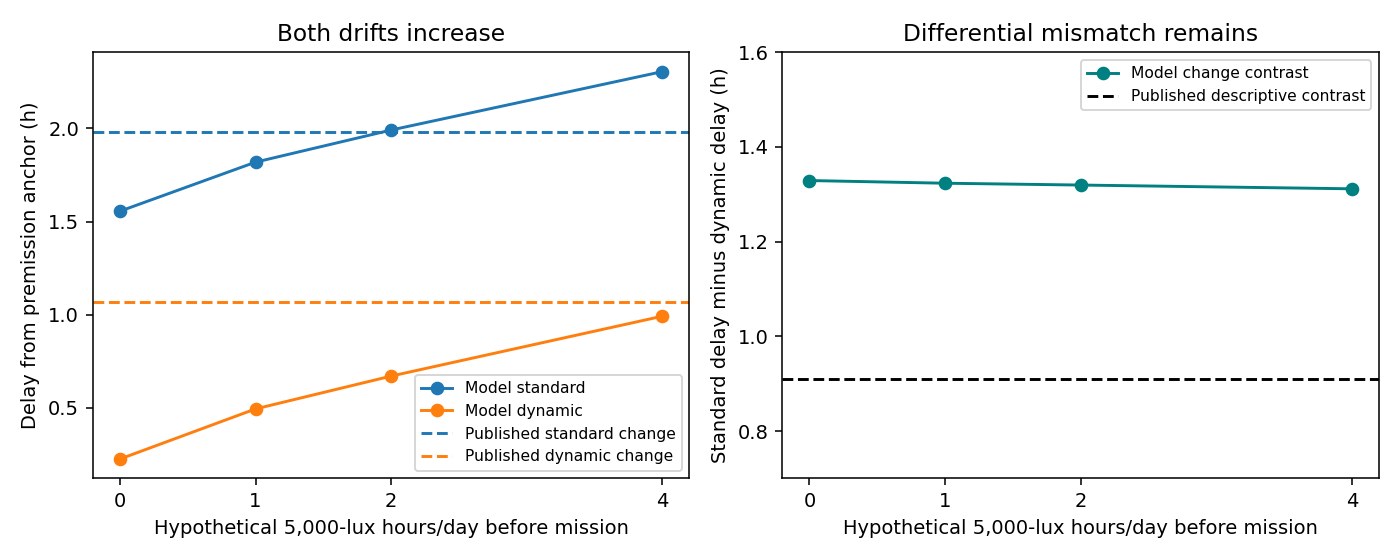

In [6]:
"""Fixed hypothetical outdoor-light profiles; known-target sensitivity, not fitting."""
import numpy as np,pandas as pd,json,pathlib,io,contextlib
# Reuse alignment definitions from the preceding notebook cell.

def outdoor_premission(hours,tau=24.2,lux=5000.,center_clock=13.):
    if hours not in [0,1,2,4]:raise ValueError('Fixed durations are 0,1,2,4 hours')
    # Wake begins at 07:00; daylight pulse centered at 13:00.
    midpoint=center_clock-7;begin=midpoint-hours/2;end=midpoint+hours/2
    segments=[(0,16,150.),(16,24,0.)] if hours==0 else [(0,begin,150.),(begin,end,lux),(end,16,150.),(16,24,0.)]
    state=np.array([1.,0.,.5]);ts=[];xs=[]
    for day in range(-21,0):
        for a,b,I in segments:
            t,y=evolve(day*24+a,day*24+b,state,tau,I);state=y[:,-1]
            if day>=-7:ts.extend(t[:-1]);xs.extend(y[0,:-1])
    return state,circular_mean((minima(ts,xs)+7)%24)

def execute_profiles():
    rows=[]
    for hours in [0,1,2,4]:
        state,proxy=outdoor_premission(hours)
        shifts={};errors={};means={}
        for condition in ['SLS','DLS']:
            offset=float(circular_difference(PRE[condition],proxy))
            t,phase=mission_phase(state,24.2,condition)
            mapped=(phase+offset)%24
            windows=[circular_mean(mapped[(t>=(d-1)*24)&(t<(d+1)*24)]) for d in WINDOWS]
            means[condition]=float(circular_mean(windows))
            shifts[condition]=float(circular_difference(means[condition],PRE[condition]))
            errors[condition]=float(circular_difference(means[condition],MISSION[condition]))
        contrast=shifts['SLS']-shifts['DLS']
        rows.append({'outdoor_hours':hours,'premission_proxy_h':float(proxy),
          'SLS_prediction_h':means['SLS'],'DLS_prediction_h':means['DLS'],
          'SLS_delay_h':shifts['SLS'],'DLS_delay_h':shifts['DLS'],
          'benefit_change_contrast_h':contrast,'observed_change_contrast_h':.91,
          'SLS_signed_error_h':errors['SLS'],'DLS_signed_error_h':errors['DLS'],
          'mean_absolute_group_error_h':float(np.mean(np.abs(list(errors.values()))))})
    print(pd.DataFrame(rows).round(4).to_string(index=False),flush=True)
    return {'status':'hypothetical premission sensitivity; all known-target scenarios retained',
      'fixed_settings':{'tau_h':24.2,'warmup_days':21,'baseline_lux':150.,'outdoor_lux':5000.,
                       'pulse_center_clock_h':13.,'pulse_durations_h':[0,1,2,4]},'profiles':rows}


premission_profile_results=execute_profiles()
import matplotlib.pyplot as plt
profile_rows=premission_profile_results["profiles"]
fig,axes=plt.subplots(1,2,figsize=(10,4))
xs=[r["outdoor_hours"] for r in profile_rows]
axes[0].plot(xs,[r["SLS_delay_h"] for r in profile_rows],"o-",label="Model standard")
axes[0].plot(xs,[r["DLS_delay_h"] for r in profile_rows],"o-",label="Model dynamic")
axes[0].axhline(1.98,color="C0",ls="--",label="Published standard change")
axes[0].axhline(1.07,color="C1",ls="--",label="Published dynamic change")
axes[0].set(ylabel="Delay from premission anchor (h)",title="Both drifts increase")
axes[0].legend(fontsize=8)
axes[1].plot(xs,[r["benefit_change_contrast_h"] for r in profile_rows],"o-",color="teal",label="Model change contrast")
axes[1].axhline(.91,color="black",ls="--",label="Published descriptive contrast")
axes[1].set(ylabel="Standard delay minus dynamic delay (h)",title="Differential mismatch remains",ylim=(.7,1.6))
axes[1].legend(fontsize=8)
for ax in axes: ax.set_xlabel("Hypothetical 5,000-lux hours/day before mission");ax.set_xticks(xs)
fig.tight_layout();plt.show()


## Expanded Monte Carlo: 256 draws
This repeats the same assumed Normal distributions, bounds, common hypothetical premission anchor and seed. Only the numerical sampling precision increases. The intervals quantify finite Monte Carlo sampling conditional on the fixed assumptions; they do not quantify individual physiological calibration, model validity or a clinical success probability. The draws still use the original 150-lux premission assumption, not a selected outdoor-light profile.


In [7]:
# Same explicitly assumed distributions and seed as the 24-draw example.
expanded_alignment=execute_alignment(n_draws=256,seed=20261011)
def wilson_interval(k,n,z=1.96):
    p=k/n;denom=1+z*z/n
    center=(p+z*z/(2*n))/denom
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/denom
    return [max(0,center-half),min(1,center+half)]
draws=pd.DataFrame(expanded_alignment["synthetic_draws"])
diff=draws.SLS_distance_h-draws.DLS_distance_h
counts={"DLS":int((diff>1e-6).sum()),"SLS":int((diff< -1e-6).sum()),"tie":int((abs(diff)<=1e-6).sum())}
display(pd.DataFrame([{ "strategy":k,"count":v,"fraction":v/256,
 "sampling_only_95_interval":wilson_interval(v,256)} for k,v in counts.items()]))


{
  "DLS": {
    "count": 256,
    "fraction": 1.0,
    "wilson_95_interval": [
      0.9852156082782743,
      1.0
    ]
  },
  "SLS": {
    "count": 0,
    "fraction": 0.0,
    "wilson_95_interval": [
      0.0,
      0.014784391721725852
    ]
  },
  "tie": {
    "count": 0,
    "fraction": 0.0,
    "wilson_95_interval": [
      0.0,
      0.014784391721725852
    ]
  }
}
